# Pchips quickstart

[Pchips](https://github.com/vglazer/pchips) is a drop-in replacement for SciPy's
[PchipInterpolator](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.PchipInterpolator.html)
that _preserves_ monotonicity rather than _imposing_ it, which keeps it fourth-order accurate at
peaks and troughs. This notebook shows how to use it, then compares it with SciPy side by side, and
its options with each other: the cubic and quartic derivative approximations, and the M3 and M4
monotonicity constraints.

It needs `pchips`, `scipy` and `matplotlib`. Every plot is drawn from scratch, so change the data or
the options and run the cells again.

In [1]:
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import CubicSpline
from scipy.interpolate import PchipInterpolator as ScipyPchip

from pchips import PchipInterpolator

print("pchips", version("pchips"), "| scipy", version("scipy"))

pchips 1.0.7 | scipy 1.16.1


## Using it

`PchipInterpolator` takes the same arguments as SciPy's, plus two options: `approx_order`
(`"cubic"`, the default, or `"quartic"`) and `mono_constraint` (`"M3"`, the default, or `"M4"`).
The result is a SciPy `CubicHermiteSpline`, so it evaluates, differentiates, integrates and finds
roots the same way.

In [2]:
x = np.linspace(0, 2*np.pi, 11)
interp = PchipInterpolator(x, np.sin(x))

print("value at pi/2:        ", interp(np.pi / 2))
print("derivative at 0:      ", interp(0, nu=1))
print("integral over [0, pi]:", interp.integrate(0, np.pi))
print("roots in [0, 2 pi]:   ", interp.roots(extrapolate=False))

quartic = PchipInterpolator(x, np.sin(x), approx_order="quartic", mono_constraint="M4")
print("quartic, M4 at pi/2:  ", quartic(np.pi / 2))

value at pi/2:         1.001564557670173
derivative at 0:       1.040538817871051
integral over [0, pi]: 2.0022303080685684
roots in [0, 2 pi]:    [0.         3.14159265 6.28318531]
quartic, M4 at pi/2:   0.9988846604021447


## Comparing with SciPy

A few plotting helpers, and a consistent look. SciPy is always blue and Pchips' default always orange.

In [3]:
SCIPY, PCHIPS, OTHER = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_SECONDARY, GRID = "#0b0b0b", "#52514e", "#e4e3de"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK_SECONDARY,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
    "legend.fontsize": 9, "lines.linewidth": 1.8, "font.size": 10,
})


def samples(ax, x, y):
    ax.plot(x, y, "o", color=INK, markersize=5.5, zorder=5, label="Samples")


def true_function(ax, u, v, label="True function"):
    ax.plot(u, v, "--", color=INK_SECONDARY, linewidth=1.2, label=label)


def max_errors(make, f, a, b, sizes):
    """Maximum error of make(x, f(x)) on [a, b], for each number of evenly spaced samples."""
    u = np.linspace(a, b, 20001)
    return np.array([np.max(np.abs(make(x, f(x))(u) - f(u)))
                     for x in (np.linspace(a, b, n) for n in sizes)])

### Preserving versus imposing monotonicity

#### Peaks and troughs

The peak of $\sin(x)$ falls exactly between two samples with equal values, so the data are flat there.
SciPy's interpolant _imposes_ monotonicity by setting the derivative to zero at both samples, which cuts
the peak off flat at 0.951. Pchips only _preserves_ monotonicity where the data are monotone, so it
follows the curve up to 1.002, close to the true peak of 1. The maximum error is 0.049 for SciPy and
0.0055 for Pchips.

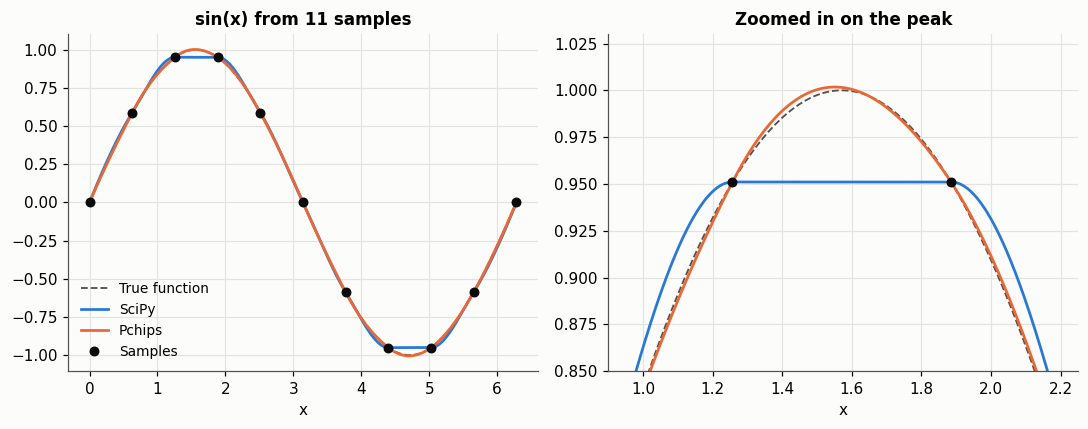

peak: SciPy 0.951, Pchips 1.002
max error: SciPy 0.0489, Pchips 0.0055


In [4]:
x = np.linspace(0, 2*np.pi, 11)
y = np.sin(x)
u = np.linspace(0, 2*np.pi, 4001)
scipy_values = ScipyPchip(x, y)(u)
pchips_values = PchipInterpolator(x, y)(u)

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
for ax in (left, right):
    true_function(ax, u, np.sin(u))
    ax.plot(u, scipy_values, color=SCIPY, label="SciPy")
    ax.plot(u, pchips_values, color=PCHIPS, label="Pchips")
    samples(ax, x, y)
    ax.set_xlabel("x")
left.set_title("sin(x) from 11 samples")
left.legend(loc="lower left")
right.set_xlim(0.9, 2.25)
right.set_ylim(0.85, 1.03)
right.set_title("Zoomed in on the peak")
fig.tight_layout()
plt.show()

print(f"peak: SciPy {scipy_values.max():.3f}, Pchips {pchips_values.max():.3f}")
print(f"max error: SciPy {np.max(np.abs(scipy_values - np.sin(u))):.4f}, "
      f"Pchips {np.max(np.abs(pchips_values - np.sin(u))):.4f}")

#### Accuracy as the samples get denser

Flattening every peak and trough limits SciPy's interpolant to $O(h^2)$ accuracy, while Pchips is
$O(h^4)$: doubling the number of samples cuts SciPy's error by a factor of 4, and Pchips' by 16. With
641 samples, the maximum error is 3.6e-6 for SciPy and 3.6e-10 for Pchips.

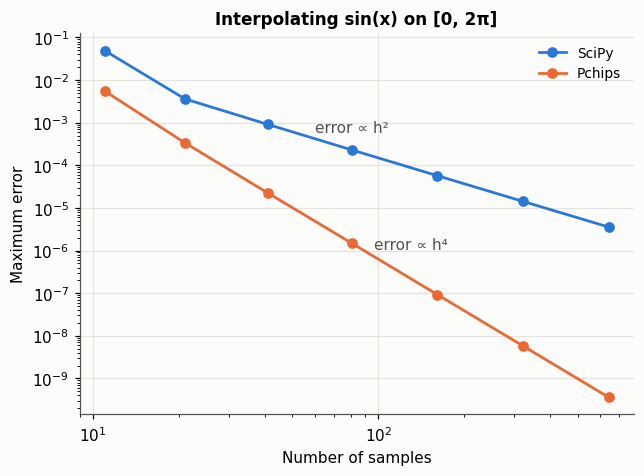

error ratio per doubling: SciPy [13.5  4.   4.   4.   4.   4. ]
                         Pchips [16.4 15.  15.3 15.8 16.  16. ]
at 641 samples: SciPy 3.6e-06, Pchips 3.6e-10


In [5]:
sizes = np.array([11, 21, 41, 81, 161, 321, 641])
scipy_errors = max_errors(ScipyPchip, np.sin, 0, 2*np.pi, sizes)
pchips_errors = max_errors(PchipInterpolator, np.sin, 0, 2*np.pi, sizes)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.loglog(sizes, scipy_errors, "o-", color=SCIPY, markersize=6, label="SciPy")
ax.loglog(sizes, pchips_errors, "o-", color=PCHIPS, markersize=6, label="Pchips")
ax.annotate("error ∝ h²", (sizes[3], scipy_errors[3]), textcoords="offset points",
            xytext=(0, 12), ha="center", color=INK_SECONDARY)
ax.annotate("error ∝ h⁴", (sizes[3], pchips_errors[3]), textcoords="offset points",
            xytext=(14, -4), ha="left", color=INK_SECONDARY)
ax.set_xlabel("Number of samples")
ax.set_ylabel("Maximum error")
ax.set_title("Interpolating sin(x) on [0, 2π]")
ax.legend()
plt.show()

print("error ratio per doubling: SciPy", np.round(scipy_errors[:-1] / scipy_errors[1:], 1))
print("                         Pchips", np.round(pchips_errors[:-1] / pchips_errors[1:], 1))
print(f"at {sizes[-1]} samples: SciPy {scipy_errors[-1]:.1e}, Pchips {pchips_errors[-1]:.1e}")

The classic data sets used below, from the `data` directory of the repository:

In [6]:
DATA = {
    "hyman": (np.array([-2.8, -2.0, -1.2, -0.4, 0.4, 1.2, 2.0, 2.8, 3.6]),
              np.array([5.933936e-04, 1.831564e-02, 1.300097e-01, 8.521438e-01, 8.521438e-01, 1.300097e-01, 1.831564e-02, 5.933936e-04, 6.233393e-06])),
    "moler": (np.array([1, 2, 3, 4, 5, 5.5, 7, 8, 9, 9.5, 10]),
              np.array([0, 0, 0, 0.5, 0.4, 1.2, 1.2, 0.1, 0, 0.3, 0.6])),
    "akima": (np.array([3, 5, 6, 8, 9, 11, 12, 14, 15]),
              np.array([10, 10, 10, 10, 10.5, 15, 50, 60, 85])),
    "rpn14": (np.array([7.99, 8.09, 8.19, 8.7, 9.2, 10.0, 12.0, 15.0, 20.0]),
              np.array([0.0, 2.76429e-5, 4.37498e-2, 0.169183, 0.469428, 0.943740, 0.998636, 0.999919, 0.999994])),
    "titanium": (np.array([595, 635, 695, 795, 855, 875, 895, 915, 935, 985, 1035, 1075]),
              np.array([0.644, 0.652, 0.644, 0.694, 0.907, 1.336, 2.169, 1.598, 0.916, 0.607, 0.603, 0.608])),
}

#### Monotone data stay monotone

On monotone data, both PCHIPs give a monotone interpolant with no overshoot, unlike a cubic spline,
which dips to 4.74 on data which never go below 10 and bulges above 60 between the samples at 50 and 60.

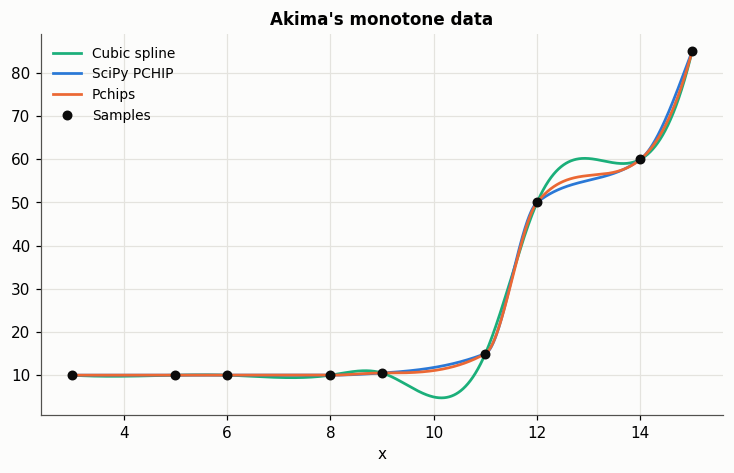

Cubic spline: monotone False, range [4.74, 85.00]
SciPy PCHIP: monotone True, range [10.00, 85.00]
Pchips: monotone True, range [10.00, 85.00]


In [7]:
x, y = DATA["akima"]
u = np.linspace(x.min(), x.max(), 4001)
curves = [("Cubic spline", OTHER, CubicSpline(x, y)(u)),
          ("SciPy PCHIP", SCIPY, ScipyPchip(x, y)(u)),
          ("Pchips", PCHIPS, PchipInterpolator(x, y)(u))]

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, color, v in curves:
    ax.plot(u, v, color=color, label=label)
samples(ax, x, y)
ax.set_xlabel("x")
ax.set_title("Akima's monotone data")
ax.legend(loc="upper left")
plt.show()

for label, _, v in curves:
    print(f"{label}: monotone {bool(np.all(np.diff(v) >= -1e-12))}, range [{v.min():.2f}, {v.max():.2f}]")

#### The price: overshoot on rough data

Relaxing the constraint near peaks and troughs means Pchips can overshoot the data there. On smooth
data the overshoot is small and usually closer to the truth, as for $\sin(x)$ above. On rough data it
can be large: on these 20 random values in [0.08, 0.93], from SciPy's own `test_overshoot`, Pchips
reaches 1.43, while SciPy stays within the range of the data. See
[Reasons not to switch](https://github.com/vglazer/pchips#reasons-not-to-switch) in the README.

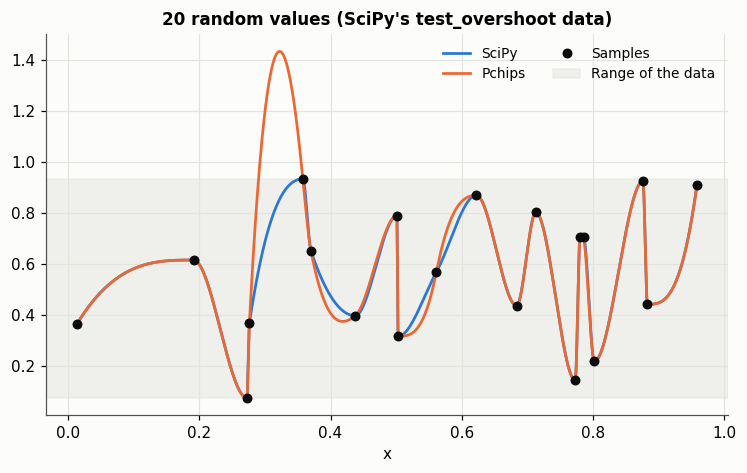

data [0.08, 0.93], SciPy [0.08, 0.93], Pchips [0.08, 1.43]


In [8]:
rng = np.random.RandomState(1234)   # the data from SciPy's test_overshoot
x = np.sort(rng.random(20))
y = rng.random(20)
u = np.linspace(x.min(), x.max(), 4001)
scipy_values = ScipyPchip(x, y)(u)
pchips_values = PchipInterpolator(x, y)(u)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(u, scipy_values, color=SCIPY, label="SciPy")
ax.plot(u, pchips_values, color=PCHIPS, label="Pchips")
samples(ax, x, y)
ax.axhspan(y.min(), y.max(), color=GRID, alpha=0.5, zorder=0, label="Range of the data")
ax.set_xlabel("x")
ax.set_title("20 random values (SciPy's test_overshoot data)")
ax.legend(loc="upper right", ncols=2)
plt.show()

print(f"data [{y.min():.2f}, {y.max():.2f}], SciPy [{scipy_values.min():.2f}, {scipy_values.max():.2f}], "
      f"Pchips [{pchips_values.min():.2f}, {pchips_values.max():.2f}]")

### Cubic versus quartic

Both derivative approximations give an $O(h^4)$ interpolant, but the quartic one has a smaller error
constant: with 641 samples of $e^{-x^2}$, the maximum error is 3.6e-9 with cubic and 2.5e-10 with
quartic (and 6.5e-6 with SciPy). With very few samples, however, quartic can be worse, since it relies
on the data being smooth over five neighbouring samples rather than four: with 11 samples, the error is
3.6e-2 with cubic and 5.2e-2 with quartic. Use quartic once the samples resolve the shape of the data.

          SciPy: 7: 4.4e-02, 11: 2.2e-02, 21: 6.3e-03, 41: 1.6e-03, 81: 4.2e-04, 161: 1.0e-04, 321: 2.6e-05, 641: 6.5e-06
  Pchips, cubic: 7: 4.7e-02, 11: 3.6e-02, 21: 3.0e-03, 41: 2.1e-04, 81: 1.3e-05, 161: 9.0e-07, 321: 5.8e-08, 641: 3.6e-09
Pchips, quartic: 7: 4.7e-02, 11: 5.2e-02, 21: 1.8e-03, 41: 8.3e-05, 81: 2.4e-06, 161: 8.4e-08, 321: 4.2e-09, 641: 2.5e-10


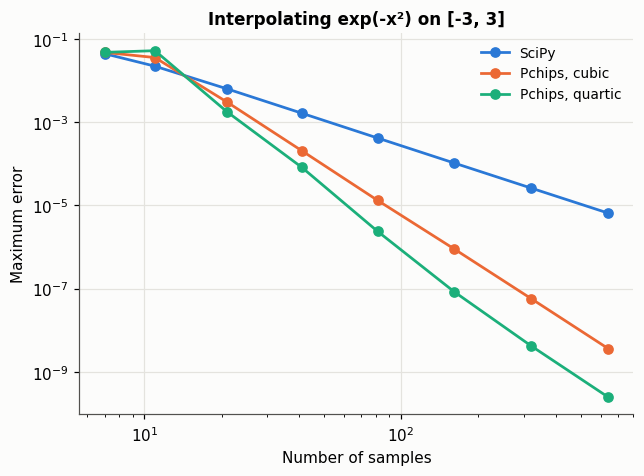

In [9]:
f = lambda x: np.exp(-x**2)
sizes = np.array([7, 11, 21, 41, 81, 161, 321, 641])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for label, color, make in [
    ("SciPy", SCIPY, ScipyPchip),
    ("Pchips, cubic", PCHIPS, PchipInterpolator),
    ("Pchips, quartic", OTHER, lambda x, y: PchipInterpolator(x, y, approx_order="quartic")),
]:
    errors = max_errors(make, f, -3, 3, sizes)
    ax.loglog(sizes, errors, "o-", color=color, markersize=6, label=label)
    print(f"{label:>15}: " + ", ".join(f"{n}: {e:.1e}" for n, e in zip(sizes, errors)))
ax.set_xlabel("Number of samples")
ax.set_ylabel("Maximum error")
ax.set_title("Interpolating exp(-x²) on [-3, 3]")
ax.legend()
plt.show()

### M3 versus M4

**Left**: on smooth, well-sampled data, M3 and M4 give the same interpolant except near a flat
inflection point, where the slope of a monotone function drops to zero between samples, as for
$x - \sin(x)$ at $x = 0$. There, M3 clips the derivatives to keep the interpolant monotone and loses
accuracy: with 41 samples, the maximum error is 1.8e-5 with M3 and 6.7e-6 with M4. SciPy, which imposes
monotonicity everywhere, is shown for comparison.

**Right**: the price of M4. To stay fourth-order accurate, M4 allows derivatives which can make the
interpolant non-monotone on rough monotone data. On this data set, which increases at every sample, the
M4 interpolant decreases by 0.11 between $x = 3.5$ and $x = 4.5$, while the M3 interpolant and SciPy's
stay monotone.

x - sin(x): SciPy max error 1.3e-04
x - sin(x): M4 max error 6.7e-06
x - sin(x): M3 max error 1.8e-05
monotone data: SciPy largest decrease 0.000
monotone data: M3 largest decrease 0.000
monotone data: M4 largest decrease 0.108


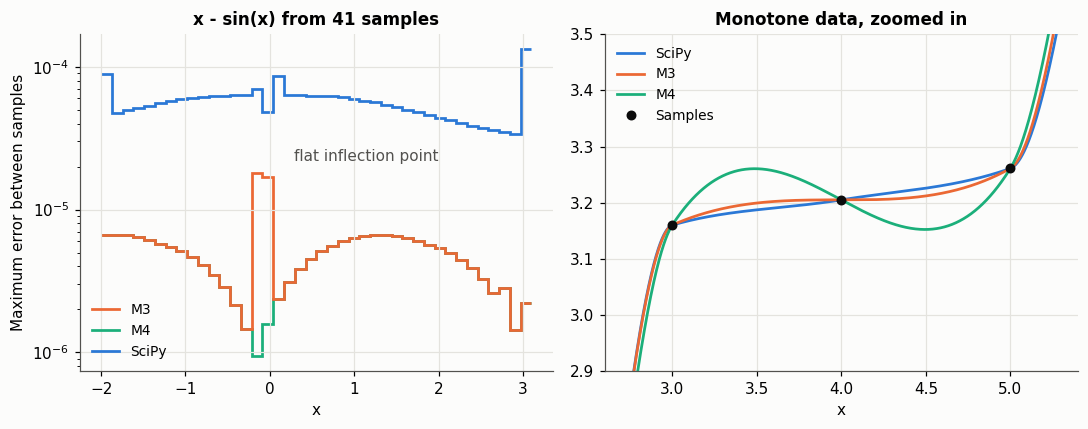

In [10]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))

# M4 is more accurate at a flat inflection point. Plot the maximum error in each interval between
# samples; M3 is drawn on top since the two coincide away from x = 0
f = lambda x: x - np.sin(x)
x = np.linspace(-2, 3.1, 41)
intervals = [np.linspace(x[i], x[i+1], 201) for i in range(len(x) - 1)]
for label, color, interp in [("SciPy", SCIPY, ScipyPchip(x, f(x))),
                             ("M4", OTHER, PchipInterpolator(x, f(x), mono_constraint="M4")),
                             ("M3", PCHIPS, PchipInterpolator(x, f(x), mono_constraint="M3"))]:
    errors = [np.max(np.abs(interp(v) - f(v))) for v in intervals]
    left.stairs(errors, x, color=color, linewidth=1.8, label=label, baseline=None)
    print(f"x - sin(x): {label} max error {max(errors):.1e}")
left.set_yscale("log")
left.annotate("flat inflection point", (0, 1.8e-5), textcoords="offset points",
              xytext=(16, 8), color=INK_SECONDARY)
left.set_xlabel("x")
left.set_ylabel("Maximum error between samples")
left.set_title("x - sin(x) from 41 samples")
handles, labels = left.get_legend_handles_labels()
left.legend(handles[::-1], labels[::-1], loc="lower left")

# M4 can break monotonicity on rough monotone data
y = np.array([0.534, 1.144, 1.229, 3.16, 3.205, 3.261, 4.597, 4.803, 6.408, 6.74])
x = np.arange(len(y), dtype=float)
u = np.linspace(x.min(), x.max(), 4001)
for label, color, interp in [("SciPy", SCIPY, ScipyPchip(x, y)),
                             ("M3", PCHIPS, PchipInterpolator(x, y, mono_constraint="M3")),
                             ("M4", OTHER, PchipInterpolator(x, y, mono_constraint="M4"))]:
    v = interp(u)
    right.plot(u, v, color=color, label=label)
    print(f"monotone data: {label} largest decrease {np.max(np.maximum.accumulate(v) - v):.3f}")
samples(right, x, y)
right.set_xlim(2.6, 5.4)
right.set_ylim(2.9, 3.5)
right.set_xlabel("x")
right.set_title("Monotone data, zoomed in")
right.legend(loc="upper left")
fig.tight_layout()
plt.show()

### Classic data sets

The data sets loaded above, which the tests also use. Each plot compares SciPy with Pchips' default
settings (and, for Akima's data, the quartic approximation too).

- **Hyman**: nine samples of $e^{-x^2}$, with the peak between the samples at $\pm 0.4$. SciPy cuts the
  peak off flat at 0.852, an error of 0.148, while Pchips reaches 0.988, an error of 0.012. Away from the
  peak, nine samples are too few for either interpolant to follow the curve closely, and Pchips is off by
  up to 0.128 at $x = 1.06$.
- **Moler**: rough, non-monotone data with plateaus and sharp turns. SciPy stays within the data, flat
  across the plateau at 1.2. Pchips treats the two samples at 1.2 as either side of a peak and rounds it
  off up to 1.57, then dips to -0.118 between the samples at 0.1 and 0. If the plateau and the zero floor
  are real features of the data, SciPy is the better choice here.
- **Akima**: monotone data with a sharp rise, one of the test cases in Huynh's paper. All three
  interpolants are monotone and stay within the data. SciPy and Pchips' default differ by at most 1.8, on
  the final rise from 60 to 85. The quartic approximation, which draws on more neighbouring samples,
  stands out between the samples at 50 and 60: it levels off close to 60 (59.4 at $x = 13.5$, against
  57.0 and 56.8), then rises more steeply to 85.
- **RPN 14**: monotone data which rise steeply and then level off, from Fritsch and Carlson's paper on
  monotone interpolation, and the other test case in Huynh's paper. SciPy and Pchips are both monotone
  and differ by at most 0.036, mostly near the bottom of the rise.
- **Titanium**: a sharp peak which happens to fall on a sample, so neither interpolant overshoots it, and
  both stay within the data. They differ by at most 0.12, at the foot of the peak. Pchips is flat for a
  moment at the sample at $x = 855$: its derivative estimate there came out with the wrong sign for the
  rising data, so the monotonicity constraint set it to zero.

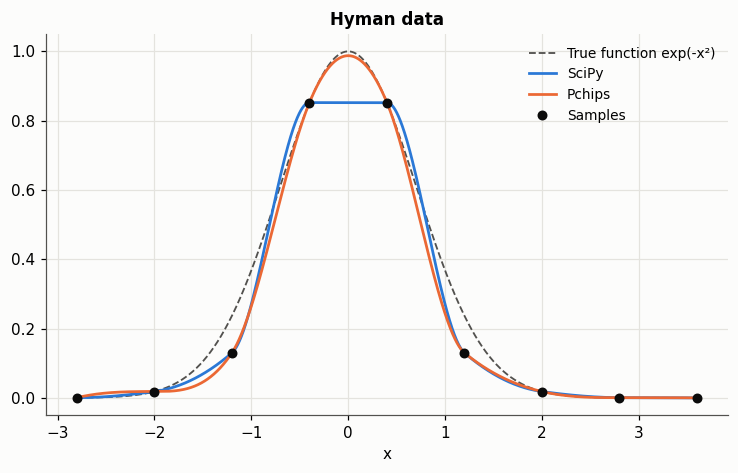

Hyman: data [6.23e-06, 0.852], SciPy [6.23e-06, 0.852], Pchips [6.23e-06, 0.988], max |Pchips - SciPy| 0.14
  SciPy max error 0.148
  Pchips max error 0.128


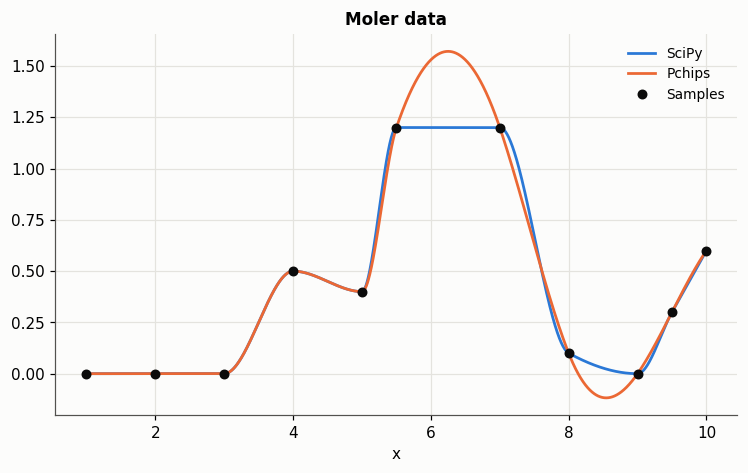

Moler: data [0, 1.2], SciPy [0, 1.2], Pchips [-0.118, 1.57], max |Pchips - SciPy| 0.37


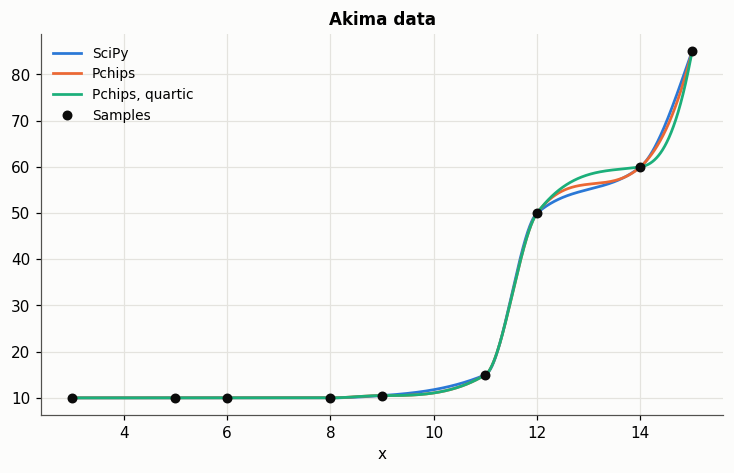

Akima: data [10, 85], SciPy [10, 85], Pchips [10, 85], Pchips, quartic [10, 85], max |Pchips - SciPy| 1.8


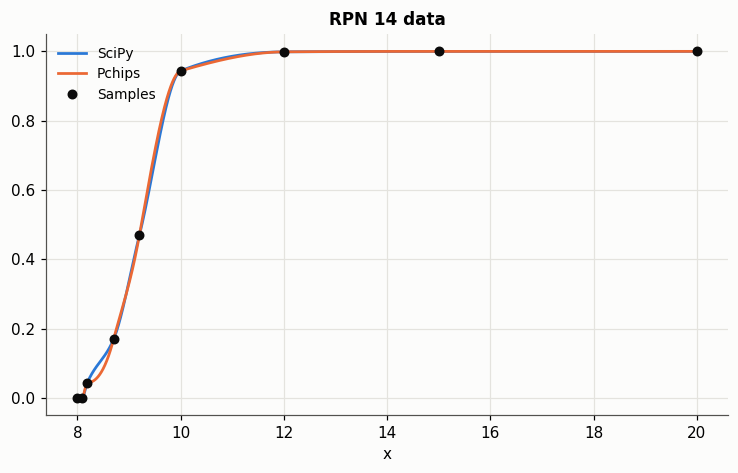

RPN 14: data [0, 1], SciPy [0, 1], Pchips [0, 1], max |Pchips - SciPy| 0.036


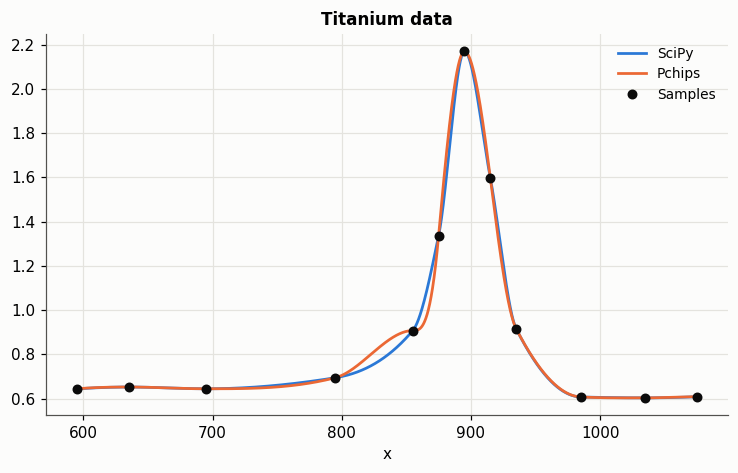

Titanium: data [0.603, 2.17], SciPy [0.603, 2.17], Pchips [0.603, 2.17], max |Pchips - SciPy| 0.12


In [11]:
TITLES = {'hyman': 'Hyman', 'moler': 'Moler', 'akima': 'Akima', 'rpn14': 'RPN 14', 'titanium': 'Titanium'}

for name, title in TITLES.items():
    x, y = DATA[name]
    u = np.linspace(x.min(), x.max(), 4001)
    curves = [("SciPy", SCIPY, ScipyPchip(x, y)(u)), ("Pchips", PCHIPS, PchipInterpolator(x, y)(u))]
    if name == "akima":
        curves.append(("Pchips, quartic", OTHER, PchipInterpolator(x, y, approx_order="quartic")(u)))

    fig, ax = plt.subplots(figsize=(8, 4.5))
    if name == "hyman":
        true_function(ax, u, np.exp(-u**2), label="True function exp(-x²)")
    for label, color, v in curves:
        ax.plot(u, v, color=color, label=label)
    samples(ax, x, y)
    ax.set_xlabel("x")
    ax.set_title(f"{title} data")
    ax.legend(loc="best")
    plt.show()

    ranges = ", ".join(f"{label} [{v.min():.3g}, {v.max():.3g}]" for label, _, v in curves)
    print(f"{title}: data [{y.min():.3g}, {y.max():.3g}], {ranges}, "
          f"max |Pchips - SciPy| {np.max(np.abs(curves[1][2] - curves[0][2])):.2g}")
    if name == "hyman":
        for label, _, v in curves:
            print(f"  {label} max error {np.max(np.abs(v - np.exp(-u**2))):.3f}")